In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import pyarrow
import duckdb

In [46]:
con = duckdb.connect()
con.read_parquet("../Data/Processed/customers_clean.parquet").create_view("customers")
con.read_parquet("../Data/Processed/orders_clean.parquet").create_view("orders");


### Unique Customer Analysis


In [47]:
#unique customers id
customers_id = con.sql(""" 
    select customer_id,
            customer_unique_id
    from customers
 """).df()

print(f"number of customer_id (customer records): {customers_id["customer_id"].count()}")
print(f"number of unique customers (customer_unique_id): {customers_id["customer_unique_id"].nunique()}")


number of customer_id (customer records): 99441
number of unique customers (customer_unique_id): 96096


In [48]:
#each row in customers is one order, so count how many rows each person has
orders_per_person = customers_id["customer_unique_id"].value_counts()
repeat_customers = (orders_per_person > 1).sum()
total_customers = customers_id["customer_unique_id"].nunique()

print(f"customers with more than one order: {repeat_customers:,} "
      f"({repeat_customers / total_customers * 100:.2f}% of unique customers)")
print(f"customers with only one order: {(orders_per_person == 1).sum():,}")


customers with more than one order: 2,997 (3.12% of unique customers)
customers with only one order: 93,099


**Customer Identifiers: `customer_id` vs. `customer_unique_id`**

- `customer_id`: Identifies a customer record in the dataset and is used to link orders to customer records.
- `customer_unique_id`: Identifies a unique customer across multiple customer records.

A single customer may have multiple `customer_id` values while sharing the same `customer_unique_id`.

**Analytical result:**

- Use `customer_id` to identify customer records and link them to orders.
- Use `customer_unique_id` to estimate the number of unique customers.

Always use `customer_unique_id` when calculating unique customers and repeat purchases.
Counting `customer_id` values as unique people would incorrectly classify repeat customers.

Only 3.12% of customers ordered more than once, so almost all customers are one-time buyers.

### Geographic Customer Distribution

#### states distribution :

In [49]:
states = con.sql(""" 
    select customer_state,
            count(distinct customer_unique_id) as customers_count,
    from customers
    group by customer_state
    order by customers_count desc
""").df()

states_population = pd.read_csv("../Data/Raw/brazil_states_population.csv")

states = states.merge(states_population,
                      left_on="customer_state",
                      right_on="states",
                      how="left").drop(columns="states")

#percent of all unique customers
states["customers_percent"] = states["customers_count"] / total_customers * 100
#number of customers per 1000 of people of state
states["customers_per_1000_residents"] = (states["customers_count"] / states["state_population"]) * 1000

print("Top 10 states with the most customers:")
display(states.head(10))

Top 10 states with the most customers:


,customer_state,customers_count,state_population,customers_percent,customers_per_1000_residents
0,SP,40302,45094866,41.939311,0.893716
1,RJ,12384,16718956,12.887113,0.740716
2,MG,11259,21119536,11.716409,0.533108
3,RS,5277,11322895,5.491384,0.466047
4,PR,4882,11320892,5.080336,0.431238
5,SC,3534,7001161,3.677572,0.504773
6,BA,3277,15344447,3.410132,0.213563
7,DF,2075,3039444,2.159299,0.682691
8,ES,1964,4016356,2.043790,0.489000
9,GO,1952,6778772,2.031302,0.287958


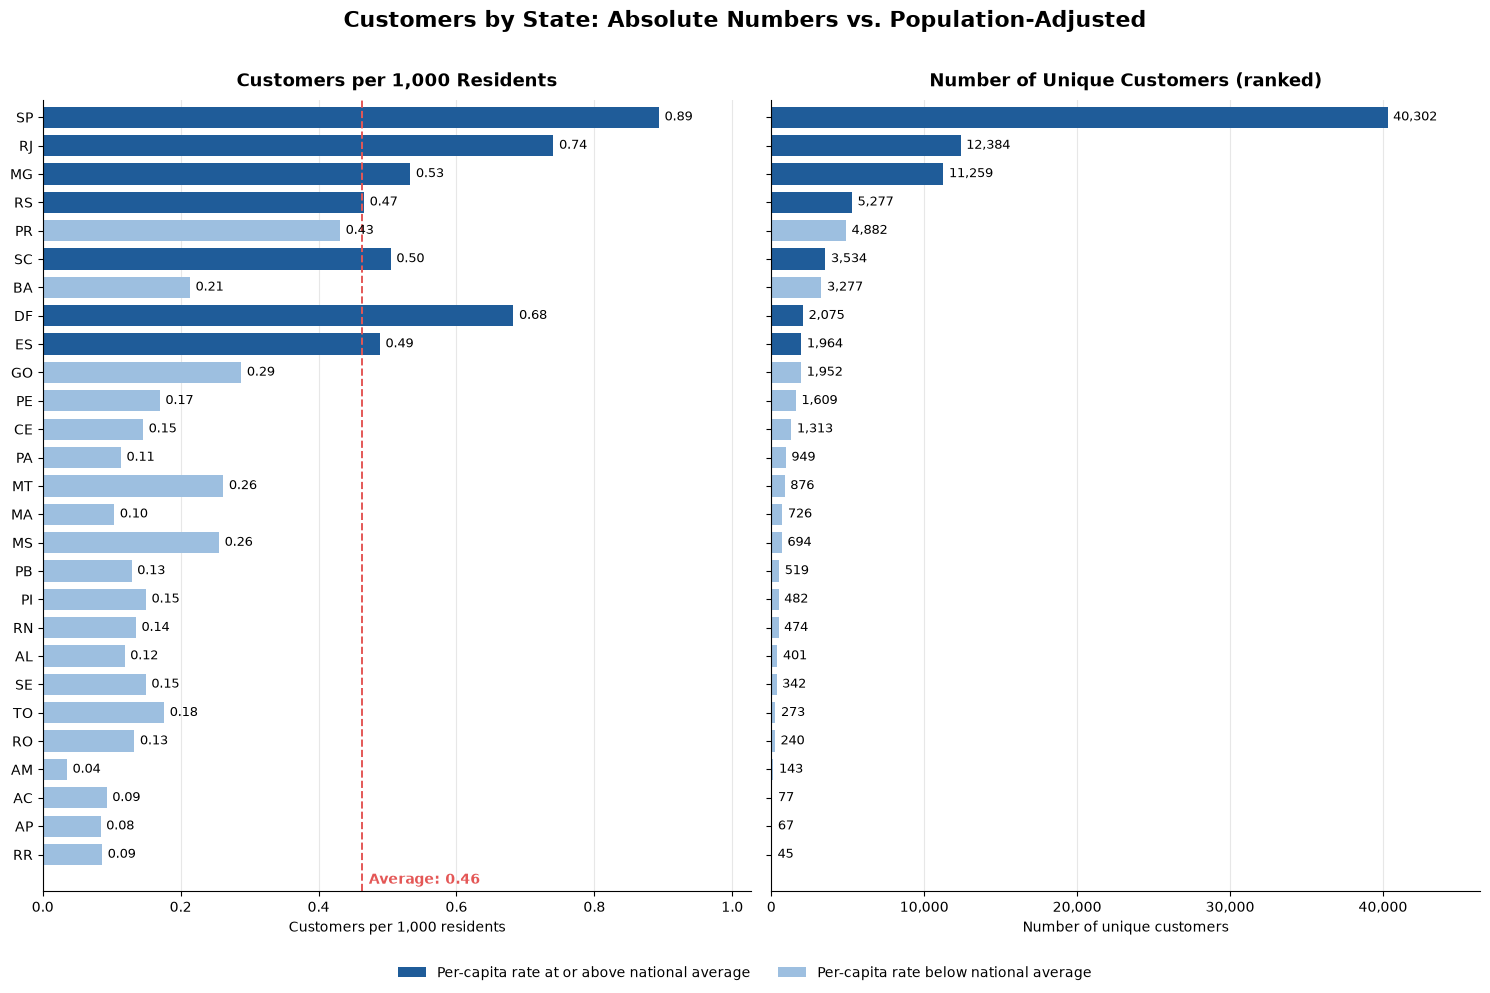

In [ ]:
#per-capita chart and ranked states chart
df = states.copy()  

# Sort by customer COUNT 
df = df.sort_values("customers_count", ascending=True).reset_index(drop=True)

# National average (total customers / total population * 1000)
national_avg = df["customers_count"].sum() / df["state_population"].sum() * 1000

# Dark blue = at/above national average per capita, light blue = below
above = df["customers_per_1000_residents"] >= national_avg
colors = np.where(above, "#1F5C99", "#9DBFE0")

y = np.arange(len(df))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 10), sharey=True)

# ---------- Left: customers per 1,000 residents (same row order as the right chart) ----------
bars1 = ax1.barh(y, df["customers_per_1000_residents"], color=colors, height=0.75)
ax1.bar_label(bars1, labels=[f"{v:.2f}" for v in df["customers_per_1000_residents"]], padding=4, fontsize=9)
ax1.axvline(national_avg, color="#E45756", linestyle="--", linewidth=1.4)
ax1.text(national_avg + 0.01, -0.9, f"Average: {national_avg:.2f}", color="#E45756",
         fontsize=10, fontweight="bold", va="center")
ax1.set_title("Customers per 1,000 Residents", fontsize=13, fontweight="bold", pad=10)
ax1.set_xlabel("Customers per 1,000 residents")
ax1.set_xlim(0, df["customers_per_1000_residents"].max() * 1.15)

# ---------- Right: number of unique customers (descending) ----------
bars2 = ax2.barh(y, df["customers_count"], color=colors, height=0.75)
ax2.bar_label(bars2, labels=[f"{n:,}" for n in df["customers_count"]], padding=4, fontsize=9)
ax2.set_title("Number of Unique Customers (ranked)", fontsize=13, fontweight="bold", pad=10)
ax2.set_xlabel("Number of unique customers")
ax2.set_xlim(0, df["customers_count"].max() * 1.15)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

# ---------- Shared styling ----------
ax1.set_yticks(y)
ax1.set_yticklabels(df["customer_state"], fontsize=10)
ax1.set_ylim(-1.3, len(df) - 0.4)

for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.legend(
    handles=[Patch(facecolor="#1F5C99", label="Per-capita rate at or above national average"),
             Patch(facecolor="#9DBFE0", label="Per-capita rate below national average")],
    loc="lower center", ncol=2, frameon=False, fontsize=10,
)

fig.suptitle("Customers by State: Absolute Numbers vs. Population-Adjusted",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

In [60]:
#state share
top_5 = states.head(5) 

print("share of the 5 largest states:")
display(top_5[["customer_state", "customers_percent"]].round(2))
print(f"combined customer share of the five largest states: {top_5['customers_percent'].sum():.2f}%")

share of the 5 largest states:


,customer_state,customers_percent
0,SP,41.94
1,RJ,12.89
2,MG,11.72
3,RS,5.49
4,PR,5.08


combined customer share of the five largest states: 77.11%


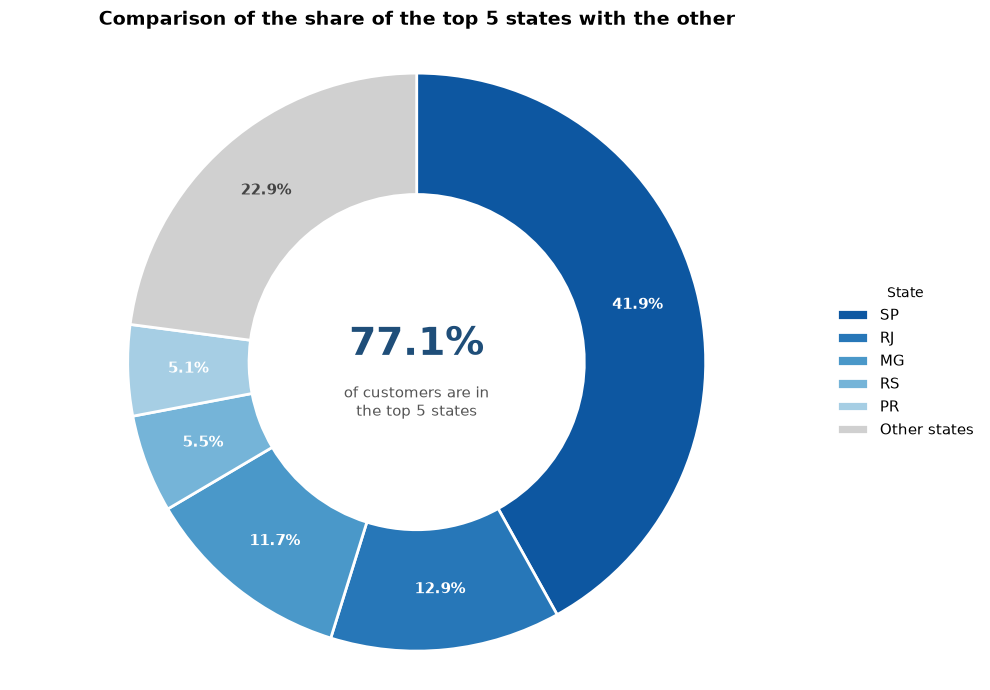

In [62]:
#pie chart of state's share
top5_percent = top_5["customers_percent"].sum()
other_percent = states["customers_percent"].sum() - top5_percent

labels = list(top_5["customer_state"]) + ["Other states"]
sizes = list(top_5["customers_percent"]) + [other_percent]

# Blue shades for the top 5 (darkest = largest), gray for the rest
colors = list(plt.cm.Blues_r(np.linspace(0.15, 0.65, 5))) + ["#D0D0D0"]

fig, ax = plt.subplots(figsize=(10, 7))

wedges, texts, autotexts = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    counterclock=False,
    autopct="%1.1f%%",
    pctdistance=0.79,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
)

for i, t in enumerate(autotexts):
    t.set_fontsize(11)
    t.set_fontweight("bold")
    t.set_color("#444444" if i == len(autotexts) - 1 else "white")

# Combined share of the top 5 in the donut center
ax.text(0, 0.06, f"{top5_percent:.1f}%", ha="center", va="center", fontsize=28, fontweight="bold", color="#1F4E79")
ax.text(0, -0.14, "of customers are in\nthe top 5 states", ha="center", va="center", fontsize=11, color="#555555")

ax.legend(
    wedges,
    labels,
    title="State",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
    fontsize=11,
)

ax.set_title(
    f"Comparison of the share of the top 5 states with the other",
    fontsize=14, fontweight="bold", pad=14,
)
ax.axis("equal")

plt.tight_layout()
plt.show()

#### State Distribution Conclusion :

The geographic analysis reveals a highly concentrated distribution of Olist's unique customers across Brazilian states.

São Paulo (SP) has the largest customer base, with 40,302 unique customers, accounting for approximately 41.94% of all customers. Rio de Janeiro (RJ) and Minas Gerais (MG) rank second and third, with 12,384 and 11,259 customers, respectively. The considerable gap between São Paulo and the other states highlights its dominant position in Olist's customer distribution.

**Population size explains much of the ranking.** The national average is about **0.46 customers per 1,000 residents**. Large states like BA (3,277 customers) and PR (4,882) have many customers in absolute terms but fall below this average, meaning their numbers come mostly from large populations rather than strong market penetration.

**Some smaller states punch above their size.** DF ranks 8th in customer count but 3rd per capita (0.68), and SC (0.50) and ES (0.49) also beat the national average despite modest totals.

**Penetration is strongest in the South-East.** SP, RJ, MG, RS, SC, ES, and DF are the only states at or above the average. Northern and North-Eastern states are well below it (AM is lowest at 0.04), pointing to weak market reach there.

**Takeaway:** looking only at raw customer counts overstates the importance of populous states and hides the strong performance of smaller ones like DF. The per-capita view shows where the platform's reach is genuinely high, and where there is room to grow (e.g. BA, PE, CE, and the North).

Furthermore, the five states with the highest customer counts (SP, RJ, MG, RS, and PR) collectively account for approximately **77.1% of the total customer base**, while all remaining states represent only 22.9%.

These findings indicate that Olist's customer base is geographically concentrated in a relatively small number of Brazilian states, particularly São Paulo. This concentration should be considered in marketing and market development decisions.

However, customer distribution alone does not determine the business potential or profitability of each state. Further analysis of order volume and purchasing behavior is required to identify regional differences and evaluate potential market expansion opportunities.

**source**(for population): IBGE, Estimativas da População Residente, reference date July 1, 2017.

#### cities distribution :

In [63]:
cities = con.sql(""" 
    select customer_city,
            customer_state,
            count(distinct customer_unique_id) as customers_count,
    from customers
    group by customer_state,customer_city
    order by customers_count desc
""").df()

#percent of all unique customers
cities["customers_percent"] = cities["customers_count"] / total_customers * 100


print("top 10 cities with most customers:")
display(cities.head(10).round(2))
print(f"total share of top 10 cities: {cities['customers_percent'].head(10).sum():.2f}%")

top 10 cities with most customers:


,customer_city,customer_state,customers_count,customers_percent
0,sao paulo,SP,14984,15.59
1,rio de janeiro,RJ,6620,6.89
2,belo horizonte,MG,2672,2.78
3,brasilia,DF,2069,2.15
4,curitiba,PR,1465,1.52
5,campinas,SP,1398,1.45
6,porto alegre,RS,1326,1.38
7,salvador,BA,1209,1.26
8,guarulhos,SP,1153,1.20
9,sao bernardo do campo,SP,908,0.94


total share of top 10 cities: 35.18%


In [64]:
#check top 100 cities distribution
top_100_cities = cities.head(100)

cities_per_state = top_100_cities["customer_state"].value_counts()
display(cities_per_state.to_frame())
print(f"number of states with at least one top-100 city: {len(cities_per_state)}")

,count
customer_state,
SP,47
RJ,11
MG,10
RS,5
PR,4
SC,4
ES,4
BA,2
DF,1


number of states with at least one top-100 city: 21


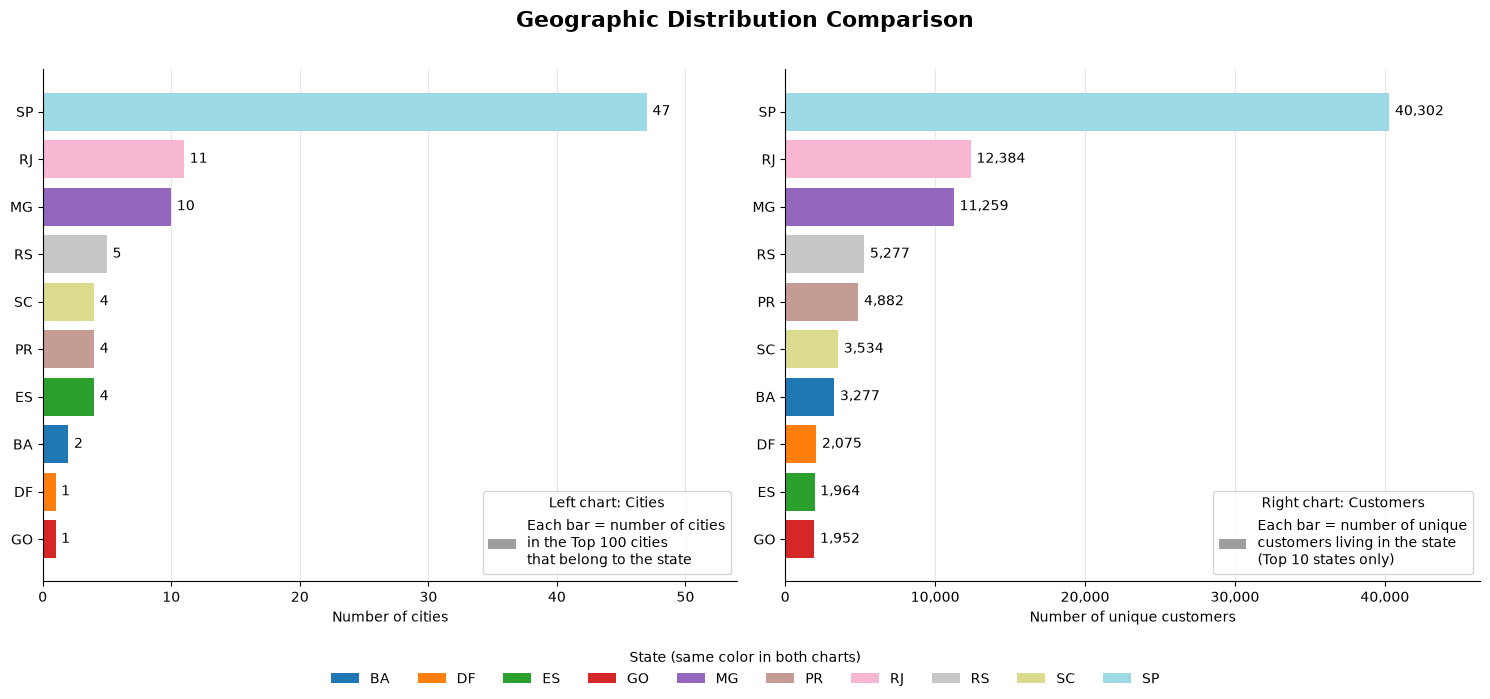

In [ ]:
#Comparison chart of the distribution of the number of top cities within states versus the ranked states 

# Prepare data (largest at the bottom after sorting ascending, so it ends up on top in barh)
cities_df = (
    top_100_cities["customer_state"]
    .value_counts()
    .head(10)
    .rename_axis("customer_state")
    .reset_index(name="count")
    .sort_values("count", ascending=True)
)

customers_df = (
    states.head(10)
    .sort_values("customers_count", ascending=True)
)

# One color per state, shared by both charts so the same state is easy to match
all_states = sorted(set(cities_df["customer_state"]) | set(customers_df["customer_state"]))
palette = plt.cm.tab20(np.linspace(0, 1, len(all_states)))
state_color = dict(zip(all_states, palette))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Left: state distribution among the top 100 cities
bars_left = axes[0].barh(
    cities_df["customer_state"],
    cities_df["count"],
    color=[state_color[s] for s in cities_df["customer_state"]],
)
axes[0].bar_label(bars_left, padding=4, fontsize=10)
axes[0].set_xlabel("Number of cities")
axes[0].set_xlim(0, cities_df["count"].max() * 1.15)

# Right: top 10 states by customer count
bars_right = axes[1].barh(
    customers_df["customer_state"],
    customers_df["customers_count"],
    color=[state_color[s] for s in customers_df["customer_state"]],
)
axes[1].bar_label(bars_right, labels=[f"{n:,}" for n in customers_df["customers_count"]], padding=4, fontsize=10)
axes[1].set_xlabel("Number of unique customers")
axes[1].set_xlim(0, customers_df["customers_count"].max() * 1.15)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

# Shared styling
for ax in axes:
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Geographic Distribution Comparison", fontsize=16, fontweight="bold")

from matplotlib.patches import Patch

#Explanatory legend inside each chart
#    (lower right is empty because the longest bars are at the top)
axes[0].legend(
    handles=[Patch(facecolor="#9E9E9E", label="Each bar = number of cities\nin the Top 100 cities\nthat belong to the state")],
    loc="lower right",
    frameon=True,
    fontsize=10,
    title="Left chart: Cities",
    title_fontsize=10,
)

axes[1].legend(
    handles=[Patch(facecolor="#9E9E9E", label="Each bar = number of unique\ncustomers living in the state\n(Top 10 states only)")],
    loc="lower right",
    frameon=True,
    fontsize=10,
    title="Right chart: Customers",
    title_fontsize=10,
)

#shared color legend for the states, at the bottom of the figure
state_handles = [Patch(facecolor=state_color[s], label=s) for s in all_states]
fig.legend(
    handles=state_handles,
    title="State (same color in both charts)",
    loc="lower center",
    ncol=len(all_states),
    frameon=False,
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.08, 1, 0.97])  # leave room for the bottom legend
plt.show()

#### Business Conclusion

The geographic analysis reveals a considerable concentration of Olist's customer base in a relatively small number of Brazilian cities and states.

Sao Paulo is the leading city, with 14,984 unique customers, accounting for approximately 15.59% of the total customer base. This is more than twice the number of customers in Rio de Janeiro, which ranks second with 6,620 customers. Overall, the top 10 cities account for approximately 35.18% of all unique customers.

The distribution of the top 100 cities further highlights this geographic concentration.Top-100 cities are found in 21 of the 27 states, but SP, RJ and MG together hold 68 of them. Sao Paulo (SP) accounts for 47 of these cities, followed by Rio de Janeiro (RJ) with 11 and Minas Gerais (MG) with 10. Together, these three states represent 68 of the 100 cities with the highest customer counts.

The comparison chart also reveals a similar pattern between the two geographic indicators. States with more cities represented in the top 100 generally have higher customer counts. Sao Paulo clearly dominates both charts, while Rio de Janeiro and Minas Gerais also maintain leading positions. This suggests that the concentration of customers at the state level is also reflected in the distribution of cities with the highest customer counts.

From a business perspective, these findings indicate that major urban centers, particularly those in Sao Paulo, are important regions for Olist's customer base. Management could consider these areas when planning regional marketing activities, operational capacity, and delivery services.

However, a high customer count or a large number of cities in the top 100 does not necessarily indicate higher profitability or better business performance. Further analysis of order volume, revenue, average order value, and delivery costs is necessary to evaluate the actual business potential of each region.

#### customer counts with order counts:

In [ ]:
customers_orders = con.sql(""" 
    select 
        c.customer_state,
        count(distinct o.order_id) as orders_count,
        count(distinct c.customer_unique_id) as customers_count,
        count(distinct o.order_id) * 100 / sum(count(distinct o.order_id)) over() as orders_percent,
        count(distinct c.customer_unique_id) * 100 / sum(count(distinct c.customer_unique_id)) over() as customers_percent
    from orders AS o 
    left join customers AS c
        on o.customer_id = c.customer_id
    group by c.customer_state
    order by customers_count desc, orders_count desc
""").df()

#check share difference
customers_orders["share_difference"] = customers_orders["orders_percent"] - customers_orders["customers_percent"]

In [69]:
print("states with order volume and customer volume :")
display(customers_orders.head(10))

states with order volume and customer volume :


,customer_state,orders_count,customers_count,orders_percent,customers_percent,share_difference
0,SP,41746,40302,41.980672,41.921861,0.058811
1,RJ,12852,12384,12.924247,12.881751,0.042496
2,MG,11635,11259,11.700405,11.711534,-0.011128
3,RS,5466,5277,5.496727,5.489099,0.007628
4,PR,5045,4882,5.073360,5.078223,-0.004862
5,SC,3637,3534,3.657445,3.676042,-0.018597
6,BA,3380,3277,3.399000,3.408713,-0.009712
7,DF,2140,2075,2.152030,2.158401,-0.006371
8,ES,2033,1964,2.044428,2.042939,0.001489
9,GO,2020,1952,2.031355,2.030457,0.000898


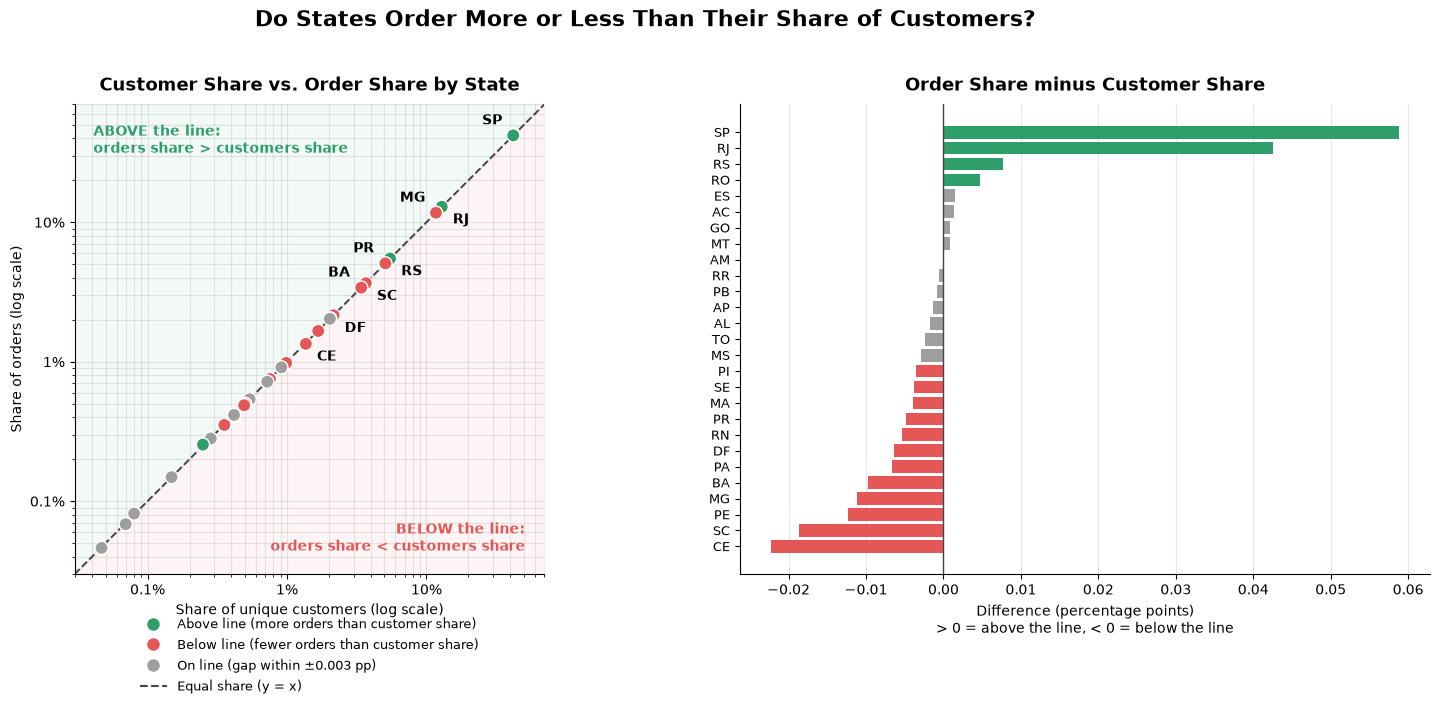

In [ ]:
#Chart of Order Volume vs. Customer Volume Alignment
#based on their shares for each state

df = customers_orders.copy()

# Points closer to the line than this (in percentage points) count as "on the line"
tol = 0.003

def position(d):
    if d > tol:
        return "Above"
    if d < -tol:
        return "Below"
    return "On line"

df["position"] = df["share_difference"].apply(position)
colors = {"Above": "#2E9E6B", "Below": "#E45756", "On line": "#9E9E9E"}

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1.15, 1]}
)

# ---------- Left: scatter (log-log) ----------
lo, hi = 0.03, 70
x = np.array([lo, hi])

ax1.plot(x, x, linestyle="--", color="#444444", linewidth=1.4, zorder=1)
ax1.fill_between(x, x, hi, color="#2E9E6B", alpha=0.06, zorder=0)   # above the line
ax1.fill_between(x, lo, x, color="#E45756", alpha=0.06, zorder=0)   # below the line

ax1.scatter(
    df["customers_percent"],
    df["orders_percent"],
    c=df["position"].map(colors),
    s=90,
    edgecolor="white",
    linewidth=1,
    zorder=3,
)

# Label only the important states: the 8 largest and the 4 with the biggest gap
to_label = set(df.nlargest(8, "customers_percent").index) | set(
    df.reindex(df["share_difference"].abs().sort_values(ascending=False).index).head(4).index
)
for i in to_label:
    r = df.loc[i]
    # alternate label side so neighbors don't collide
    dx, dy = (8, -12) if i % 2 else (-8, 8)
    ax1.annotate(
        r["customer_state"],
        (r["customers_percent"], r["orders_percent"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="left" if dx > 0 else "right",
        fontsize=10,
        fontweight="bold",
    )

ax1.text(0.04, 0.96, "ABOVE the line:\norders share > customers share",
         transform=ax1.transAxes, va="top", fontsize=10, color="#2E9E6B", fontweight="bold")
ax1.text(0.96, 0.04, "BELOW the line:\norders share < customers share",
         transform=ax1.transAxes, va="bottom", ha="right", fontsize=10, color="#E45756", fontweight="bold")

ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlim(lo, hi)
ax1.set_ylim(lo, hi)
ax1.set_aspect("equal")
ax1.set_xticks([0.1, 1, 10])
ax1.set_yticks([0.1, 1, 10])
ax1.set_xticklabels(["0.1%", "1%", "10%"])
ax1.set_yticklabels(["0.1%", "1%", "10%"])
ax1.set_xlabel("Share of unique customers (log scale)")
ax1.set_ylabel("Share of orders (log scale)")
ax1.set_title("Customer Share vs. Order Share by State", fontsize=13, fontweight="bold", pad=10)
ax1.grid(alpha=0.3, which="both")
ax1.set_axisbelow(True)
ax1.spines[["top", "right"]].set_visible(False)

legend_items = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=colors["Above"], markersize=10, label="Above line (more orders than customer share)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=colors["Below"], markersize=10, label="Below line (fewer orders than customer share)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=colors["On line"], markersize=10, label=f"On line (gap within ±{tol} pp)"),
    Line2D([0], [0], linestyle="--", color="#444444", label="Equal share (y = x)"),
]
ax1.legend(handles=legend_items, loc="lower center", bbox_to_anchor=(0.5, -0.28), frameon=False, fontsize=9.5)

# ---------- Right: the actual gap per state ----------
d = df.sort_values("share_difference")
ax2.barh(d["customer_state"], d["share_difference"], color=d["position"].map(colors))
ax2.axvline(0, color="#444444", linewidth=1)
ax2.set_title("Order Share minus Customer Share", fontsize=13, fontweight="bold", pad=10)
ax2.set_xlabel("Difference (percentage points)\n> 0 = above the line, < 0 = below the line")
ax2.tick_params(axis="y", labelsize=9)
ax2.grid(axis="x", alpha=0.3)
ax2.set_axisbelow(True)
ax2.spines[["top", "right"]].set_visible(False)

fig.suptitle("Do States Order More or Less Than Their Share of Customers?", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### Business Conclusion

The analysis compared the distribution of unique customers and orders across Brazilian states to identify potential mismatches between customer concentration and order volume.

Overall, **the results show a strong alignment between customer share and order share across most states**. The scatter plot indicates that most states are positioned close to the equal-share reference line, suggesting that their contribution to total orders is generally proportional to their share of unique customers.

Sao Paulo (SP) and Rio de Janeiro (RJ), which have the largest customer bases, show slightly higher order shares than customer shares, with differences of approximately 0.059 and 0.042 percentage points, respectively. On the other hand, states such as Minas Gerais (MG), Santa Catarina (SC), Bahia (BA), and Parana (PR) have slightly lower order shares relative to their customer shares. However, these differences remain small.

The comparison charts also confirm that there is no substantial mismatch between customer distribution and order distribution across the states. While some regional differences exist, they do not indicate a significant imbalance in the overall geographic distribution of orders.

From a business perspective, the findings suggest that **Olist's order volume generally follows its geographic customer distribution**. Therefore, states with large customer bases also contribute proportionally to total orders. Based on these results alone, there is no strong evidence that any major state generates substantially fewer orders than its customer population would suggest.

However, this analysis focuses on order volume and customer distribution, not customer loyalty, revenue, or profitability. Additional analysis would be required to evaluate these aspects of regional business performance.

## Summary Report

### Objective
Understand where Olist's unique customers are located across Brazilian states and cities, measure how concentrated the customer base is, adjust for state population size, and test whether order volume is proportional to customer volume in each state.

### Key Metrics

| Metric | Result |
|---|---|
| Customer records (`customer_id`) | 99,441 |
| Unique customers (`customer_unique_id`) | 96,096 |
| Customers with more than one order | 2,997 (3.12%) |
| Largest state: São Paulo (SP) | 40,302 customers (41.94%) |
| Top 5 states (SP, RJ, MG, RS, PR) | 77.11% of customers |
| Largest city: São Paulo | 14,984 customers (15.59%) |
| Top 10 cities | 35.18% of customers |
| Top-100 cities located in SP / RJ / MG | 47 / 11 / 10 (68 of 100) |
| States with at least one top-100 city | 21 of 27 |
| National penetration | about 0.46 customers per 1,000 residents |

### Key Findings

1. **Customer counts are based on `customer_unique_id`.** Counting `customer_id` would overstate the customer base by about 3,300 records, because one person can have several `customer_id` values.

2. **The customer base is highly concentrated.** SP alone holds about 42% of customers, and five states hold more than three quarters. The same pattern appears at city level: São Paulo city has more than twice the customers of Rio de Janeiro (6,620; 6.89%), and ten cities account for over a third of the base.

3. **Concentration is also broad within the leading states.** SP, RJ and MG contain 68 of the 100 largest customer cities, so the leading states have many strong cities rather than one dominant one. Even so, 21 of 27 states have at least one top-100 city, so demand is not limited to the South-East.

4. **Population size explains much of the ranking, but not all of it.** SP (0.89), RJ (0.74), DF (0.68), MG (0.53), SC (0.50) and ES (0.49) are at or above the national average of 0.46 customers per 1,000 residents. DF is only 8th by customer count but 3rd per capita. BA (0.21) and PR (0.43) have large absolute numbers that come mostly from large populations rather than strong penetration, and the North and North-East are far below average (AM is the lowest at 0.04).

5. **Orders follow customers closely.** State order shares and customer shares differ by less than 0.06 percentage points. SP (+0.059) and RJ (+0.042) are slightly above proportional, while MG, SC, BA and PR are slightly below. These gaps are very small, so no state shows a meaningful mismatch between customers and orders.

6. **Almost all customers buy once.** Only 3.12% placed a second order, so the order volume in each state is driven almost entirely by customer acquisition, not by repeat buying.

## Business Conclusion

Olist's demand is concentrated in the South-East, with São Paulo as the clear core at both state and city level. Because orders track customers almost one-to-one, the number of customers in a region is a reliable indicator of its order volume, and no state is generating noticeably more or fewer orders than its customer base would suggest.

The per-capita view changes the picture of where growth is available. High raw counts in BA and PR reflect population size, not strong reach, while DF, SC and ES already perform above the national average despite modest totals. The North and North-East have the lowest penetration, which suggests the largest untapped potential, provided that logistics and delivery conditions allow profitable service there. That is a hypothesis these data cannot confirm.

### Recommendations

- **Protect the core.** Prioritize marketing, seller coverage, and delivery capacity in SP, RJ and MG, where most orders are generated. A service problem in these states would affect most of the business.
- **Treat high-penetration, smaller markets as proven.** DF, SC and ES show that Olist can reach above-average penetration outside the three largest states, and they are lower-risk places to extend campaigns.
- **Test growth in low-penetration, high-population states.** BA, PE and CE combine large populations with low per-capita reach. Run small, measurable pilots (targeted promotions, delivery-time improvements) before committing large budgets.
- **Raise repeat purchases.** With only 3.12% of customers returning, retention is the largest lever that is independent of geography, and it applies in every state.